##  Session setup

In [1]:
import base64
import os
from pathlib import Path
import subprocess
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

try:
    import google.colab  # type: ignore
    from google.colab import drive
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

try:
    from dotenv import load_dotenv
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "python-dotenv"])
    from dotenv import load_dotenv

REPO_URL = "https://github.com/RAM-AS-RAP/ucs35-mudibo-ml.git"
REPO_BRANCH = "feature/data-cleaning"

if IN_COLAB:
    drive.mount("/content/drive")

    ENV_PATHS = [
        Path("/content/drive/MyDrive/capstone-data/.env"),
        Path("/content/drive/MyDrive/AgriSence/.env"),
        Path("/content/drive/MyDrive/.env"),
        Path("/content/.env"),
    ]
    loaded_env_paths = [str(path) for path in ENV_PATHS if path.exists() and load_dotenv(path)]

    github_token = os.getenv("GITHUB_TOKEN") or os.getenv("GH_TOKEN")
    try:
        from google.colab import userdata
        github_token = github_token or userdata.get("GITHUB_TOKEN") or userdata.get("GH_TOKEN")
    except Exception:
        pass

    if not github_token:
        searched_paths = "\n".join(f"- {path}" for path in ENV_PATHS)
        raise RuntimeError(
            "Private repo clone requires GITHUB_TOKEN or GH_TOKEN in the Colab runtime.\n"
            "Add it with Colab Secrets, or create a Drive .env file at one of these paths:\n"
            f"{searched_paths}"
        )

    REPO_DIR = Path("/content/AgriSence")
    %cd /content
    if REPO_DIR.exists():
        !rm -rf {REPO_DIR}

    auth_header = base64.b64encode(f"x-access-token:{github_token}".encode()).decode()
    subprocess.run(
        [
            "git",
            "-c",
            f"http.https://github.com/.extraheader=AUTHORIZATION: basic {auth_header}",
            "clone",
            "-b",
            REPO_BRANCH,
            REPO_URL,
            str(REPO_DIR),
        ],
        check=True,
    )
    repo_root = REPO_DIR
else:
    current_dir = Path.cwd().resolve()
    candidates = [current_dir, *current_dir.parents]
    repo_root = next(
        (
            path for path in candidates
            if (path / "pyproject.toml").exists() and (path / "src" / "agrisence").exists()
        ),
        None,
    )
    if repo_root is None:
        raise FileNotFoundError("Start this notebook from inside the AgriSence repository.")

%cd {repo_root}
load_dotenv(repo_root / ".env")
sys.path.insert(0, str(repo_root / "src"))

if Path("requirements.txt").exists():
    %pip install -r requirements.txt
else:
    raise FileNotFoundError("requirements.txt was not found in the repository root.")

from agrisence.config.constants import MARKETS, CROPS
from agrisence.preprocessing.cleaning import (
    filter_target_scope, normalize_units, resolve_pricetype,
    resolve_label_overlap, build_monthly_calendar, quantify_missingness,
    diagnose_missing_gap_lengths, forward_fill_short_gaps,
    seasonal_interpolate_medium_gaps, list_missing_rows, flag_outliers_iqr,
)
from agrisence.preprocessing.aggregation import aggregate_to_monthly

sns.set_theme(style="whitegrid")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content
/content/AgriSence


### 1. Load raw dataset

In [2]:
WFP_URL = (
    'https://data.humdata.org/dataset/wfp-food-prices-for-kenya/resource/'
    '517ee1bf-2437-4f8c-aa1b-cb9925b9d437/download/wfp_food_prices_ken.csv'
)
raw_df = pd.read_csv(WFP_URL)
if raw_df.iloc[0].astype(str).str.match(r'^#').any():
    raw_df = raw_df.iloc[1:].reset_index(drop=True)
raw_df['market'] = raw_df['market'].str.strip().str.title()
raw_df['commodity'] = raw_df['commodity'].str.strip().str.title()
raw_df['date'] = pd.to_datetime(raw_df['date'])
print(raw_df.shape)

(27343, 16)


### 2. Filter to target markets and relabel commodities

In [3]:
RAW_COMMODITY_MAP = {'Maize (White)': 'Maize', 'Beans (Dry)': 'Beans'}
df = filter_target_scope(raw_df, MARKETS, RAW_COMMODITY_MAP)
print(df.shape)
df.groupby(['market', 'commodity']).size()

(3835, 16)


market   commodity              
Kisumu   Beans                      323
         Maize                      325
         Potatoes (Irish)           161
         Sorghum                    161
Mombasa  Beans                      310
         Maize                      312
         Potatoes (Irish)             3
         Sorghum                      3
Nairobi  Bananas                      1
         Beans                      315
         Bread                      178
         Cooking Fat                  1
         Fuel (Diesel)               67
         Fuel (Kerosene)             67
         Fuel (Petrol-Gasoline)      67
         Maize                      360
         Maize Flour                  1
         Meat (Beef)                  1
         Meat (Goat)                  1
         Milk (Cow, Pasteurized)    178
         Oil (Vegetable)            178
         Onions (Red)                 1
         Potatoes (Irish)           129
         Rice                         1
         Sorghum                    147
         Sugar                        1
         Tomatoes                     1
         Wheat Flour                  1
Nakuru   Beans                      191
         Maize                      226
         Potatoes (Irish)            62
         Sorghum                     62
dtype: int64

### 3. Normalize units to price per kg

In [4]:
df = normalize_units(df)
df[['commodity', 'unit', 'price', 'price_per_kg']].sample(min(10, len(df)), random_state=42)

Unhandled unit values; price_per_kg set to NaN: ['400 G', '50 KG', '500 ML', 'L', 'Unit']


,commodity,unit,price,price_per_kg
4612,Oil (Vegetable),L,196.00,NaN
4115,Potatoes (Irish),50 KG,3550.00,NaN
1276,Beans,90 KG,4490.00,49.888889
4985,Beans,90 KG,7600.00,84.444444
2742,Sorghum,90 KG,4640.00,51.555556
350,Beans,90 KG,3000.00,33.333333
405,Beans,90 KG,3071.88,34.132000
335,Maize,KG,15.25,15.250000
5710,Beans,KG,88.36,88.360000
1183,Potatoes (Irish),50 KG,2146.52,NaN


### 4. Verify unit normalization closed the scale gap

In [5]:
comparison = df.groupby(['commodity'])['price_per_kg'].agg(['mean', 'std', 'min', 'max'])
print(comparison)


                               mean        std         min         max
commodity                                                             
Bananas                         NaN        NaN         NaN         NaN
Beans                     61.312604  15.710130   27.810000  113.244444
Bread                           NaN        NaN         NaN         NaN
Cooking Fat              104.000000        NaN  104.000000  104.000000
Fuel (Diesel)                   NaN        NaN         NaN         NaN
Fuel (Kerosene)                 NaN        NaN         NaN         NaN
Fuel (Petrol-Gasoline)          NaN        NaN         NaN         NaN
Maize                     29.157482   9.169929   11.430000   60.020000
Maize Flour               62.000000        NaN   62.000000   62.000000
Meat (Beef)              431.000000        NaN  431.000000  431.000000
Meat (Goat)              533.170000        NaN  533.170000  533.170000
Milk (Cow, Pasteurized)         NaN        NaN         NaN         NaN
Oil (V

### 5. Resolve pricetype to wholesale only

In [6]:
df = resolve_pricetype(df, preferred='Wholesale')
print(df.shape)

market   commodity                pricetype
Kisumu   Beans                    Wholesale    323
         Maize                    Wholesale    325
         Potatoes (Irish)         Wholesale    161
         Sorghum                  Wholesale    161
Mombasa  Beans                    Wholesale    310
         Maize                    Wholesale    312
         Potatoes (Irish)         Wholesale      3
         Sorghum                  Wholesale      3
Nairobi  Bananas                  Retail         1
         Beans                    Retail         1
                                  Wholesale    314
         Bread                    Retail       178
         Cooking Fat              Retail         1
         Fuel (Diesel)            Retail        67
         Fuel (Kerosene)          Retail        67
         Fuel (Petrol-Gasoline)   Retail        67
         Maize                    Retail         1
                                  Wholesale    359
         Maize Flour              Reta

### 6. Resolve any remaining label-overlap duplicates

In [7]:
df = resolve_label_overlap(df)
print(df.shape)
dupes = df[df.duplicated(subset=['market', 'commodity', 'date'], keep=False)]
print(f'Remaining duplicates: {len(dupes)}')

Overlapping (market, commodity, date) rows averaged: 2008
(2082, 17)
Remaining duplicates: 0


### 7. Build the full monthly calendar and quantify missingness

In [8]:
df['month'] = df['date'].dt.to_period('M').dt.to_timestamp()
calendar = build_monthly_calendar(MARKETS, CROPS, df['month'].min(), df['month'].max())
missingness_summary = quantify_missingness(df, calendar)
missingness_summary

Overall missingness: 13.52%


,market,commodity,missing_months,expected_months,missing_proportion
0,Kisumu,Beans,31,196,0.158163
1,Kisumu,Maize,28,196,0.142857
2,Mombasa,Beans,28,196,0.142857
3,Mombasa,Maize,17,196,0.086735
4,Nairobi,Beans,17,196,0.086735
5,Nairobi,Maize,6,196,0.030612
6,Nakuru,Beans,53,196,0.270408
7,Nakuru,Maize,32,196,0.163265


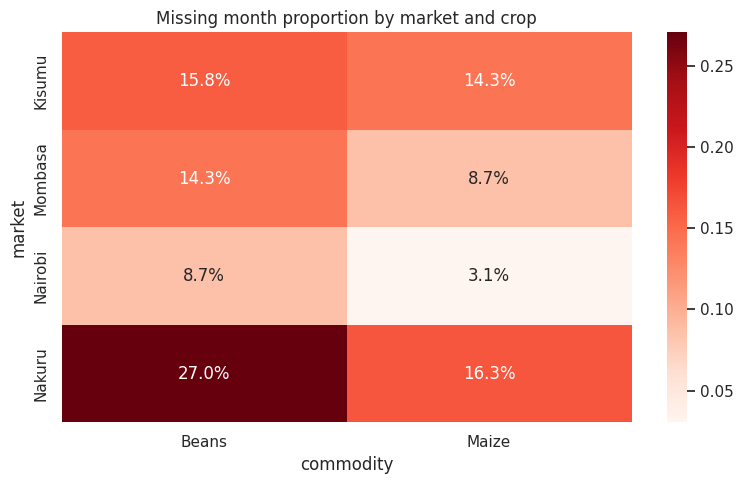

In [9]:
plt.figure(figsize=(8, 5))
sns.heatmap(missingness_summary.pivot(index='market', columns='commodity', values='missing_proportion'), annot=True, fmt='.1%', cmap='Reds')
plt.title('Missing month proportion by market and crop')
plt.tight_layout()
plt.show()

### 8. Aggregate to monthly frequency

In [10]:
monthly_df = aggregate_to_monthly(df)
monthly_df.tail()

,market,commodity,month,avg_price_per_kg
2077,Nakuru,Sorghum,2019-11-01,38.888889
2078,Nakuru,Sorghum,2019-12-01,38.888889
2079,Nakuru,Sorghum,2020-01-01,39.513889
2080,Nakuru,Sorghum,2020-02-01,36.666667
2081,Nakuru,Sorghum,2020-03-01,30.000000


### 9. Reindex against the full calendar to expose gaps explicitly

In [11]:
full_panel = calendar.merge(monthly_df, on=['market', 'commodity', 'month'], how='left')
print(f'Total expected rows: {len(calendar)}')
print(f'Rows with an observed price: {full_panel["avg_price_per_kg"].notna().sum()}')

Total expected rows: 1568
Rows with an observed price: 1356


### 10. Diagnose missing-month gap lengths

In [12]:
gap_runs = diagnose_missing_gap_lengths(full_panel, value_col='avg_price_per_kg')
print(gap_runs['gap_length_months'].describe())
gap_runs.groupby('gap_length_months').size().sort_index()

count    35.000000
mean      6.057143
std       8.516223
min       1.000000
25%       1.000000
50%       2.000000
75%       6.500000
max      30.000000
Name: gap_length_months, dtype: float64


,0
gap_length_months,
1,15
2,7
3,1
4,1
5,2
8,1
9,2
14,1
22,1


### 11. Tiered gap handling: short (forward-fill), medium (seasonal), long (leave missing)

<p>Short gaps (2 months or fewer) are forward-filled. Medium gaps (3-6 months) are filled only from the same calendar month one or two years earlier. Future-year values and forward interpolation are excluded to preserve walk-forward, no-future-information discipline. If no prior-year reference exists, the value remains missing. Gaps longer than 6 months are left as missing rather than fabricated.</p>

In [13]:
full_panel = forward_fill_short_gaps(full_panel, value_col='avg_price_per_kg', max_gap_months=2)
full_panel = seasonal_interpolate_medium_gaps(full_panel, value_col='avg_price_per_kg', min_gap_months=3, max_gap_months=6)

full_panel['impute_method'] = 'observed'
full_panel.loc[full_panel['was_imputed'], 'impute_method'] = 'short_gap_ffill'
full_panel.loc[full_panel['was_interpolated'], 'impute_method'] = 'medium_gap_seasonal'
full_panel.loc[full_panel['avg_price_per_kg'].isna(), 'impute_method'] = 'long_gap_unfilled'

print(full_panel['impute_method'].value_counts())
print(f'Remaining missing after tiered fill: {full_panel["avg_price_per_kg"].isna().sum()}')

impute_method
observed               1356
long_gap_unfilled       166
short_gap_ffill          29
medium_gap_seasonal      17
Name: count, dtype: int64
Remaining missing after tiered fill: 166


In [14]:
from agrisence.preprocessing.cleaning import load_fews_gap_files, fill_gaps_from_fews_files

# FEWS's API returns 403 Forbidden from this environment, so these are manually-saved
# Postman responses for the same gap queries loaded from disk instead of a live call.
FEWS_GAP_FILES = {
    ("Kisumu", "Maize"): "results/artifacts/fews_raw/kisumu_maize.json",
    ("Mombasa", "Maize"): "results/artifacts/fews_raw/mombasa_maize.json",
    ("Nairobi", "Beans"): "results/artifacts/fews_raw/nairobi_beans.json",
    ("Nakuru", "Beans"): "results/artifacts/fews_raw/nakuru_beans.json",
}

fews_gap_data = load_fews_gap_files(FEWS_GAP_FILES)

Kisumu Maize: loaded 22 records from results/artifacts/fews_raw/kisumu_maize.json, covering 2020-04-01 00:00:00 to 2022-01-01 00:00:00
Mombasa Maize: loaded 9 records from results/artifacts/fews_raw/mombasa_maize.json, covering 2020-04-01 00:00:00 to 2020-12-01 00:00:00
Nairobi Beans: loaded 8 records from results/artifacts/fews_raw/nairobi_beans.json, covering 2020-05-01 00:00:00 to 2020-12-01 00:00:00
Nakuru Beans: loaded 9 records from results/artifacts/fews_raw/nakuru_beans.json, covering 2020-04-01 00:00:00 to 2020-12-01 00:00:00


In [15]:
# These 48 rows are substituted directly from FEWS with no validated agreement check
# against WFP, since no overlapping observation exists to calibrate against (see Section 3).
full_panel = fill_gaps_from_fews_files(full_panel, fews_gap_data)
full_panel['impute_method'].value_counts()

FEWS file fill summary Kisumu Maize: 22 of 22 originally missing months filled; 0 remain unfilled
FEWS file fill summary Mombasa Maize: 9 of 9 originally missing months filled; 0 remain unfilled
FEWS file fill summary Nairobi Beans: 8 of 8 originally missing months filled; 0 remain unfilled
FEWS file fill summary Nakuru Beans: 9 of 47 originally missing months filled; 38 remain unfilled


,count
impute_method,
observed,1356
long_gap_unfilled,118
external_fill_fews,48
short_gap_ffill,29
medium_gap_seasonal,17


In [16]:
from agrisence.preprocessing.cleaning import load_fews_extension_files, extend_panel_with_fews

FEWS_EXTENSION_FILES = {
    ("Kisumu", "Beans"): "results/artifacts/fews_raw/kisumu_beans_ext.json",
    ("Kisumu", "Maize"): "results/artifacts/fews_raw/kisumu_maize_ext.json",
    ("Mombasa", "Beans"): "results/artifacts/fews_raw/mombasa_beans_ext.json",
    ("Mombasa", "Maize"): "results/artifacts/fews_raw/mombasa_maize_ext.json",
    ("Nairobi", "Beans"): "results/artifacts/fews_raw/nairobi_beans_ext.json",
    ("Nairobi", "Maize"): "results/artifacts/fews_raw/nairobi_maize_ext.json",
    ("Nakuru", "Beans"): "results/artifacts/fews_raw/nakuru_beans_ext.json",
    ("Nakuru", "Maize"): "results/artifacts/fews_raw/nakuru_maize_ext.json",
}

fews_ext_data = load_fews_extension_files(FEWS_EXTENSION_FILES)
full_panel = extend_panel_with_fews(full_panel, fews_ext_data)
full_panel.groupby(['market', 'commodity'])['month'].max()

Kisumu Beans: loaded 76 records from results/artifacts/fews_raw/kisumu_beans_ext.json, covering 2019-08-01 00:00:00 to 2025-11-01 00:00:00
Kisumu Maize: loaded 46 records from results/artifacts/fews_raw/kisumu_maize_ext.json, covering 2022-02-01 00:00:00 to 2025-11-01 00:00:00
Mombasa Beans: loaded 71 records from results/artifacts/fews_raw/mombasa_beans_ext.json, covering 2020-01-01 00:00:00 to 2025-11-01 00:00:00
Mombasa Maize: loaded 47 records from results/artifacts/fews_raw/mombasa_maize_ext.json, covering 2022-02-01 00:00:00 to 2025-12-01 00:00:00
Nairobi Beans: loaded 47 records from results/artifacts/fews_raw/nairobi_beans_ext.json, covering 2022-02-01 00:00:00 to 2025-12-01 00:00:00
Nairobi Maize: loaded 94 records from results/artifacts/fews_raw/nairobi_maize_ext.json, covering 2022-02-01 00:00:00 to 2025-12-01 00:00:00
Nakuru Beans: loaded 61 records from results/artifacts/fews_raw/nakuru_beans_ext.json, covering 2020-12-01 00:00:00 to 2025-12-01 00:00:00
Nakuru Maize: loade

market   commodity
Kisumu   Beans       2025-11-01
         Maize       2025-11-01
Mombasa  Beans       2025-11-01
         Maize       2025-12-01
Nairobi  Beans       2025-12-01
         Maize       2022-04-01
Nakuru   Beans       2025-12-01
         Maize       2025-12-01
Name: month, dtype: datetime64[ns]

### 12. Verify gap handling: what was filled and what remains

In [17]:
fill_counts = full_panel['impute_method'].value_counts().rename('rows')
fill_share = (fill_counts / len(full_panel)).rename('share')
print(pd.concat([fill_counts, fill_share.map('{:.2%}'.format)], axis=1), '\n')

print(f'Calendar months expected : {len(calendar)}')
print(f'Panel rows present       : {len(full_panel)}')
print(f'Absent calendar rows     : {len(calendar) - len(full_panel)}')
print(f'Null prices remaining    : {int(full_panel["avg_price_per_kg"].isna().sum())}\n')

# quantify_missingness treats a row as observed only if it carries a price.
post_fill_missingness = quantify_missingness(
    full_panel[full_panel['avg_price_per_kg'].notna()], calendar
)

fill_audit = missingness_summary.merge(
    post_fill_missingness, on=['market', 'commodity'], suffixes=('_before', '_after')
)
fill_audit['months_recovered'] = (
    fill_audit['missing_months_before'] - fill_audit['missing_months_after']
)
fill_audit[[
    'market', 'commodity', 'missing_months_before', 'months_recovered',
    'missing_months_after', 'missing_proportion_after',
]]

                              rows   share
impute_method                             
observed                      1356  72.40%
external_fill_fews_extension   374  19.97%
long_gap_unfilled               49   2.62%
external_fill_fews              48   2.56%
short_gap_ffill                 29   1.55%
medium_gap_seasonal             17   0.91% 

Calendar months expected : 1568
Panel rows present       : 1873
Absent calendar rows     : -305
Null prices remaining    : 49

Overall missingness: 3.12%


,market,commodity,missing_months_before,months_recovered,missing_months_after,missing_proportion_after
0,Kisumu,Beans,31,31,0,0.000000
1,Kisumu,Maize,28,28,0,0.000000
2,Mombasa,Beans,28,28,0,0.000000
3,Mombasa,Maize,17,17,0,0.000000
4,Nairobi,Beans,17,17,0,0.000000
5,Nairobi,Maize,6,6,0,0.000000
6,Nakuru,Beans,53,29,24,0.122449
7,Nakuru,Maize,32,7,25,0.127551


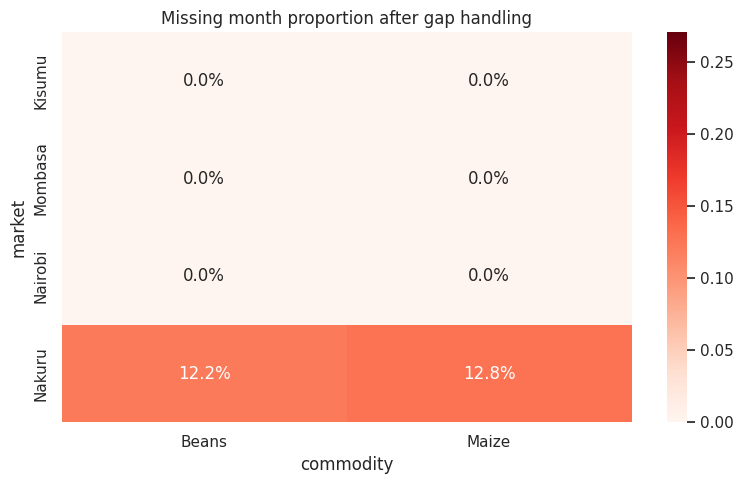

In [18]:
plt.figure(figsize=(8, 5))
sns.heatmap(
    post_fill_missingness.pivot(index='market', columns='commodity', values='missing_proportion'),
    annot=True,
    fmt='.1%',
    cmap='Reds',
    vmin=0,
    vmax=missingness_summary['missing_proportion'].max(),  # shared scale with the pre-fill heatmap
)
plt.title('Missing month proportion after gap handling')
plt.tight_layout()
plt.show()

In [19]:
absent_rows = len(calendar) - len(full_panel)
unfilled = full_panel[full_panel['avg_price_per_kg'].isna()]

print(f'Every market-crop-month present in panel: {absent_rows == 0}')
print(f'Months still without a price           : {len(unfilled)}')

if len(unfilled):
    print('\nRemaining gaps are the >6-month runs left unfilled by design:')
    display(
        unfilled.groupby(['market', 'commodity'])['month']
        .agg(first_missing='min', last_missing='max', months='count')
    )
else:
    print('\nNo missing months or prices remain.')

Every market-crop-month present in panel: False
Months still without a price           : 49

Remaining gaps are the >6-month runs left unfilled by design:


first_missing last_missing  months
market commodity                                   
Nakuru Beans        2006-01-01   2007-12-01      24
       Maize        2006-01-01   2008-01-01      25

In [20]:
missing_rows = list_missing_rows(full_panel, value_col='avg_price_per_kg')

# Leading/trailing runs are coverage limits to truncate; interior runs are true reporting gaps.
print(missing_rows['gap_position'].value_counts(), '\n')
print(
    missing_rows.groupby(['market', 'commodity', 'gap_position'])['month']
    .agg(first_missing='min', last_missing='max', months='count')
)

missing_rows[['market', 'commodity', 'month', 'gap_position', 'gap_length_months', 'month_in_gap']]

gap_position
leading    49
Name: count, dtype: int64 

                              first_missing last_missing  months
market commodity gap_position                                   
Nakuru Beans     leading         2006-01-01   2007-12-01      24
       Maize     leading         2006-01-01   2008-01-01      25


,market,commodity,month,gap_position,gap_length_months,month_in_gap
0,Nakuru,Beans,2006-01-01,leading,24,1
1,Nakuru,Beans,2006-02-01,leading,24,2
2,Nakuru,Beans,2006-03-01,leading,24,3
3,Nakuru,Beans,2006-04-01,leading,24,4
4,Nakuru,Beans,2006-05-01,leading,24,5
5,Nakuru,Beans,2006-06-01,leading,24,6
6,Nakuru,Beans,2006-07-01,leading,24,7
7,Nakuru,Beans,2006-08-01,leading,24,8
8,Nakuru,Beans,2006-09-01,leading,24,9
9,Nakuru,Beans,2006-10-01,leading,24,10


In [21]:
missing_rows_since_2014 = missing_rows[missing_rows['month'] >= '2014-01-01']

print(f'Missing rows from 2014 onward: {len(missing_rows_since_2014)}')
print(missing_rows_since_2014['gap_position'].value_counts())

missing_rows_since_2014[['market', 'commodity', 'month', 'gap_position', 'gap_length_months', 'month_in_gap']]

Missing rows from 2014 onward: 0
Series([], Name: count, dtype: int64)


,market,commodity,month,gap_position,gap_length_months,month_in_gap


### 13. Flag outliers 

In [22]:
full_panel = flag_outliers_iqr(full_panel, value_col='avg_price_per_kg')
print(f'Flagged outliers: {full_panel["is_outlier"].sum()}')
full_panel[full_panel['is_outlier']]

Flagged outliers: 112


,market,commodity,month,avg_price_per_kg,was_imputed,was_interpolated,impute_method,is_outlier
208,Kisumu,Beans,2023-05-01,190.000000,None,None,external_fill_fews_extension,True
209,Kisumu,Beans,2023-06-01,190.000000,None,None,external_fill_fews_extension,True
211,Kisumu,Beans,2023-08-01,191.111111,None,None,external_fill_fews_extension,True
212,Kisumu,Beans,2023-09-01,190.000000,None,None,external_fill_fews_extension,True
213,Kisumu,Beans,2023-10-01,200.000000,None,None,external_fill_fews_extension,True
...,...,...,...,...,...,...,...,...
1868,Nakuru,Maize,2025-08-01,55.000000,None,None,external_fill_fews_extension,True
1869,Nakuru,Maize,2025-09-01,55.000000,None,None,external_fill_fews_extension,True
1870,Nakuru,Maize,2025-10-01,55.000000,None,None,external_fill_fews_extension,True
1871,Nakuru,Maize,2025-11-01,55.000000,None,None,external_fill_fews_extension,True


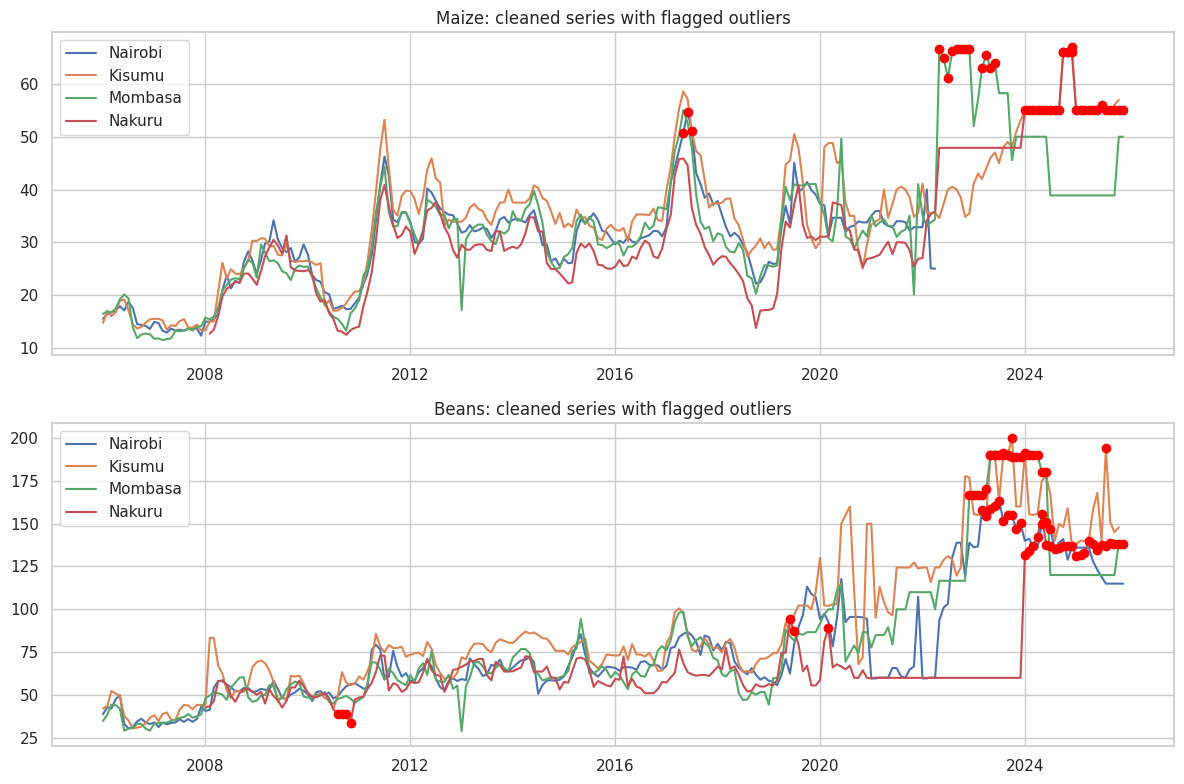

In [23]:
fig, axes = plt.subplots(len(CROPS), 1, figsize=(12, 4 * len(CROPS)))
for ax, crop in zip(axes, CROPS):
    subset = full_panel[full_panel['commodity'] == crop]
    for market in MARKETS:
        market_subset = subset[subset['market'] == market]
        ax.plot(market_subset['month'], market_subset['avg_price_per_kg'], label=market)
        outliers = market_subset[market_subset['is_outlier']]
        ax.scatter(outliers['month'], outliers['avg_price_per_kg'], color='red', zorder=5)
    ax.set_title(f'{crop}: cleaned series with flagged outliers')
    ax.legend()
plt.tight_layout()
plt.show()

### 14. Apply per-series analysis windows

Each market-crop series keeps its own first and last observed month. Leading and trailing coverage gaps are excluded without sacrificing recent data from other series. Remaining internal gaps stay explicit and are excluded from target-based training rows.

In [24]:
observed_panel = full_panel[full_panel['avg_price_per_kg'].notna()].copy()
coverage_check = (
    observed_panel.groupby(['market', 'commodity'])['month']
    .agg(
        first_observed_month='min',
        last_observed_month='max',
        observed_months='count',
    )
    .reset_index()
)
coverage_check

,market,commodity,first_observed_month,last_observed_month,observed_months
0,Kisumu,Beans,2006-01-01,2025-11-01,239
1,Kisumu,Maize,2006-01-01,2025-11-01,239
2,Mombasa,Beans,2006-01-01,2025-11-01,239
3,Mombasa,Maize,2006-01-01,2025-12-01,240
4,Nairobi,Beans,2006-01-01,2025-12-01,240
5,Nairobi,Maize,2006-01-01,2022-04-01,196
6,Nakuru,Beans,2008-01-01,2025-12-01,216
7,Nakuru,Maize,2008-02-01,2025-12-01,215


In [25]:
final_df = full_panel.merge(
    coverage_check,
    on=['market', 'commodity'],
    how='inner',
)
final_df = final_df[
    (final_df['month'] >= final_df['first_observed_month'])
    & (final_df['month'] <= final_df['last_observed_month'])
].copy()

final_missing = final_df[final_df['avg_price_per_kg'].isna()]
print(f'Per-series panel rows: {len(final_df)}')
print(f'Rows with a price: {final_df["avg_price_per_kg"].notna().sum()}')
print(f'Internal missing target rows: {len(final_missing)}')
print(f'Series retained: {coverage_check.shape[0]}')

final_df.groupby(['market', 'commodity']).agg(
    window_start=('month', 'min'),
    window_end=('month', 'max'),
    rows=('month', 'size'),
    missing_targets=('avg_price_per_kg', lambda values: values.isna().sum()),
)

Per-series panel rows: 1824
Rows with a price: 1824
Internal missing target rows: 0
Series retained: 8


window_start window_end  rows  missing_targets
market  commodity                                               
Kisumu  Beans       2006-01-01 2025-11-01   239                0
        Maize       2006-01-01 2025-11-01   239                0
Mombasa Beans       2006-01-01 2025-11-01   239                0
        Maize       2006-01-01 2025-12-01   240                0
Nairobi Beans       2006-01-01 2025-12-01   240                0
        Maize       2006-01-01 2022-04-01   196                0
Nakuru  Beans       2008-01-01 2025-12-01   216                0
        Maize       2008-02-01 2025-12-01   215                0

In [26]:
missing_target_rows = final_df[final_df['avg_price_per_kg'].isna()].copy()

print(f'Missing target rows: {len(missing_target_rows)}')
print('\nMissing targets by market and commodity:')
print(missing_target_rows.groupby(['market', 'commodity']).size().rename('missing_rows'))

print('\nMissing target dates by series:')
missing_target_summary = (
    missing_target_rows.groupby(['market', 'commodity'])['month']
    .agg(first_missing='min', last_missing='max', missing_months='count')
    .reset_index()
)
display(missing_target_summary)

print('\nExact missing-target rows:')
missing_target_rows[
    [
        'market',
        'commodity',
        'month',
        'avg_price_per_kg',
        'impute_method',
        'is_outlier',
    ]
]

Missing target rows: 0

Missing targets by market and commodity:
Series([], Name: missing_rows, dtype: int64)

Missing target dates by series:


,market,commodity,first_missing,last_missing,missing_months



Exact missing-target rows:


,market,commodity,month,avg_price_per_kg,impute_method,is_outlier


In [27]:
final_df.head()

,market,commodity,month,avg_price_per_kg,was_imputed,was_interpolated,impute_method,is_outlier,first_observed_month,last_observed_month,observed_months
0,Kisumu,Beans,2006-01-01,42.027222,False,False,observed,False,2006-01-01,2025-11-01,239
1,Kisumu,Beans,2006-02-01,43.617222,False,False,observed,False,2006-01-01,2025-11-01,239
2,Kisumu,Beans,2006-03-01,52.343333,False,False,observed,False,2006-01-01,2025-11-01,239
3,Kisumu,Beans,2006-04-01,50.852778,False,False,observed,False,2006-01-01,2025-11-01,239
4,Kisumu,Beans,2006-05-01,49.283889,False,False,observed,False,2006-01-01,2025-11-01,239


In [28]:
coverage_summary = (
    full_panel[full_panel['avg_price_per_kg'].notna()]
    .groupby(['market', 'commodity'])
    .agg(
        first_record=('month', 'min'),
        last_record=('month', 'max'),
        total_months=('month', 'count'),
    )
    .reset_index()
)

impute_breakdown = (
    full_panel[full_panel['avg_price_per_kg'].notna()]
    .groupby(['market', 'commodity', 'impute_method'])
    .size()
    .unstack(fill_value=0)
    .reset_index()
)

coverage_summary = coverage_summary.merge(impute_breakdown, on=['market', 'commodity'], how='left')
coverage_summary = coverage_summary.sort_values(['market', 'commodity']).reset_index(drop=True)
print(coverage_summary.to_string(index=False))
coverage_summary

 market commodity first_record last_record  total_months  external_fill_fews  external_fill_fews_extension  medium_gap_seasonal  observed  short_gap_ffill
 Kisumu     Beans   2006-01-01  2025-11-01           239                   0                            73                    0       165                1
 Kisumu     Maize   2006-01-01  2025-11-01           239                  22                            43                    3       168                3
Mombasa     Beans   2006-01-01  2025-11-01           239                   0                            68                    0       168                3
Mombasa     Maize   2006-01-01  2025-12-01           240                   9                            44                    5       179                3
Nairobi     Beans   2006-01-01  2025-12-01           240                   8                            44                    5       179                4
Nairobi     Maize   2006-01-01  2022-04-01           196              

,market,commodity,first_record,last_record,total_months,external_fill_fews,external_fill_fews_extension,medium_gap_seasonal,observed,short_gap_ffill
0,Kisumu,Beans,2006-01-01,2025-11-01,239,0,73,0,165,1
1,Kisumu,Maize,2006-01-01,2025-11-01,239,22,43,3,168,3
2,Mombasa,Beans,2006-01-01,2025-11-01,239,0,68,0,168,3
3,Mombasa,Maize,2006-01-01,2025-12-01,240,9,44,5,179,3
4,Nairobi,Beans,2006-01-01,2025-12-01,240,8,44,5,179,4
5,Nairobi,Maize,2006-01-01,2022-04-01,196,0,0,0,190,6
6,Nakuru,Beans,2008-01-01,2025-12-01,216,9,58,0,143,6
7,Nakuru,Maize,2008-02-01,2025-12-01,215,0,44,4,164,3


### 15. Save cleaned dataset

In [29]:
Path('artifacts').mkdir(exist_ok=True)
if IN_COLAB:
    Path('/content/drive/MyDrive/capstone-data').mkdir(parents=True, exist_ok=True)
    final_df.to_csv('/content/drive/MyDrive/capstone-data/cleaned_monthly_prices.csv', index=False)
final_df.to_csv('artifacts/training_data_snapshot.csv', index=False)